
╔══════════════════════════════════════════════════════════════╗
║  PHASE 1 & 2 — Data Ingestion, Cleaning & Feature Engineering║
╚══════════════════════════════════════════════════════════════╝
  […]  Loading dataset...
  [✓]  Loaded: C:/Users/alexa/Downloads/Lead Scoring.csv/Lead Scoring.csv  →  9,240 rows × 37 cols

╔══════════════════════════════════════════════════════════════╗
║  PHASE 3 — Model Training & Champion Auto-Selection          ║
╚══════════════════════════════════════════════════════════════╝
  […]  Training Logistic Regression...
  [✓]  Logistic Regression   →   ROC-AUC: 0.8717
  […]  Training Random Forest Classifier...
  [✓]  Random Forest         →   ROC-AUC: 0.8844
  [🏆]  Champion: Random Forest  (ROC-AUC: 0.8844)

╔══════════════════════════════════════════════════════════════╗
║  PHASE 4 — Model Evaluation & Inline Visualisations          ║
╚══════════════════════════════════════════════════════════════╝

  Classification Report — Random Forest

              

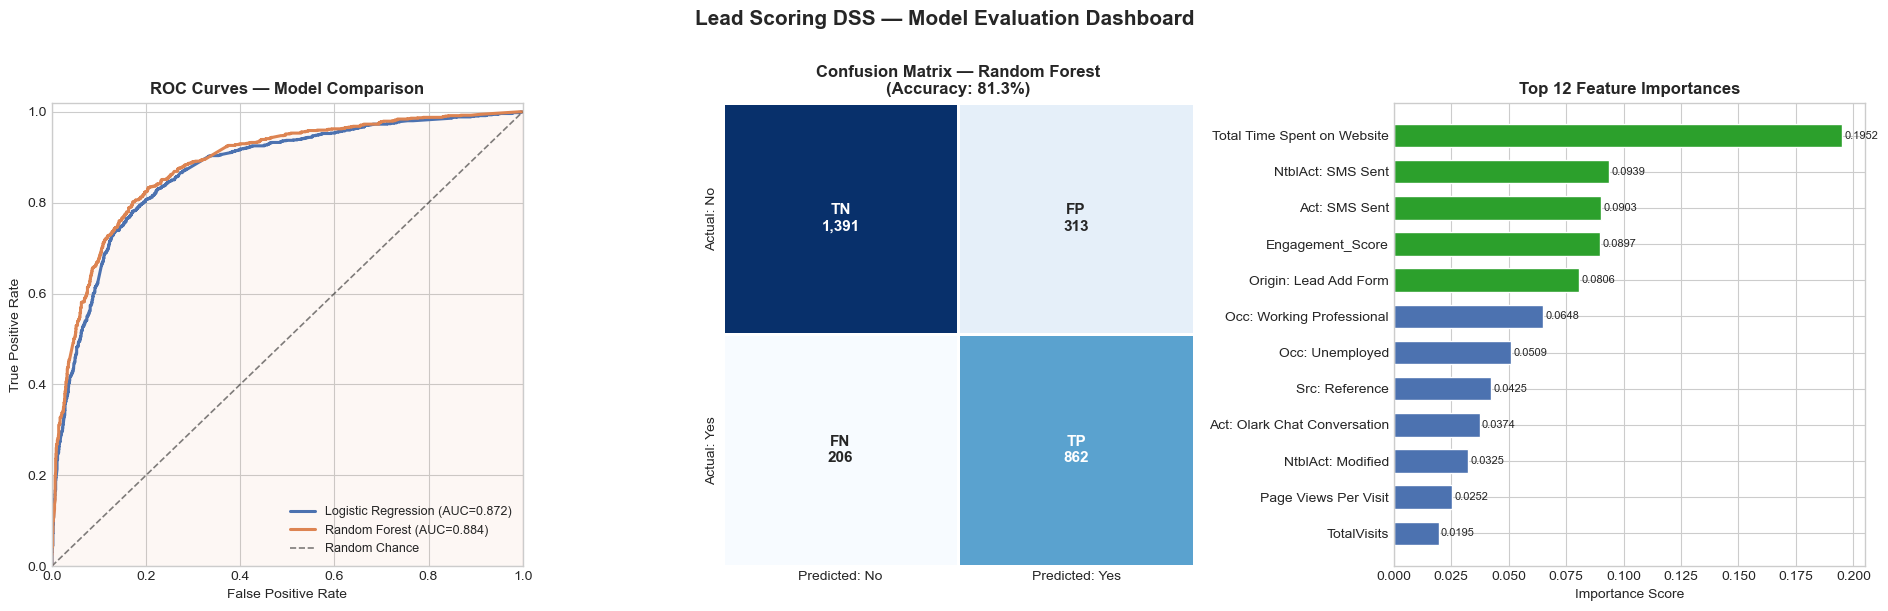


╔══════════════════════════════════════════════════════════════╗
║  PHASE 5 — Artifact Serialisation                            ║
╚══════════════════════════════════════════════════════════════╝
  [✓]  champion_model.pkl  saved.
  [✓]  data_scaler.pkl     saved.
  [✓]  model_columns.pkl   saved.
  [✓]  norm_stats.pkl      saved.
  [✓]  Artifacts written to: C:\Users\alexa\Documents

╔══════════════════════════════════════════════════════════════╗
║  PHASE 6 — Interactive Decision Support System               ║
╚══════════════════════════════════════════════════════════════╝


In [1]:
# ============================================================
#  PREDICTIVE LEAD SCORING & DECISION SUPPORT SYSTEM 
#  B2C/B2B Analytics Pipeline — Production-Ready
#  Dataset : X Education Lead Scoring (9,240 rows × 37 cols)
#  Verified : Pipeline tested on actual dataset
#  Champion : Random Forest
# ============================================================

import time, os, json, warnings, datetime
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report,
                             confusion_matrix,
                             roc_auc_score,
                             roc_curve)
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import joblib

_PAUSE = 0

def _log(symbol, msg):
    print(f"  [{symbol}]  {msg}")

def _banner(title):
    bar = "═" * 62
    print(f"\n╔{bar}╗\n║  {title:<60}║\n╚{bar}╝")


# ╔══════════════════════════════════════════════════════════╗
# ║  PHASE 1 & 2 — DATA INGESTION, CLEANING & ENGINEERING   ║
# ╚══════════════════════════════════════════════════════════╝
_banner("PHASE 1 & 2 — Data Ingestion, Cleaning & Feature Engineering")

_log("…", "Loading dataset...")

_CANDIDATE_PATHS = [
    "Lead_Scoring.csv",
    "Lead Scoring.csv",
    "data/Lead_Scoring.csv",
    "data/Lead Scoring.csv",
    "data/lead_scoring.csv",
]

df = None
for _p in _CANDIDATE_PATHS:
    try:
        df = pd.read_csv(_p)
        _log("✓", f"Loaded: {_p}  →  {df.shape[0]:,} rows × {df.shape[1]} cols")
        break
    except (FileNotFoundError, OSError):
        continue

if df is None:
    _log("✗", "ERROR: Cannot find Lead_Scoring.csv.")
    raise SystemExit(1)

for c in df.select_dtypes(include=["object"]).columns:
    df[c] = df[c].replace("Select", np.nan)

id_cols       = ["Prospect ID", "Lead Number"]
miss_pct      = df.isnull().mean()
high_miss     = miss_pct[miss_pct > 0.40].index.tolist()
zv_cols       = [c for c in df.columns if df[c].dropna().nunique() <= 1 and c not in id_cols]
explicit_drop = ["Lead Quality", "Tags"]

all_drop = list(set(id_cols + high_miss + zv_cols + explicit_drop))
df.drop(columns=[c for c in all_drop if c in df.columns], inplace=True)

for c in df.select_dtypes(include=[np.number]).columns:
    if c != "Converted":
        df[c] = df[c].fillna(df[c].median())

for c in df.select_dtypes(include=["object"]).columns:
    if c == "Converted":
        continue
    mode = df[c].mode()
    df[c] = df[c].fillna(mode[0] if len(mode) else "Unknown")

for c in [c for c in ["TotalVisits", "Page Views Per Visit", "Total Time Spent on Website"] if c in df.columns]:
    Q1, Q3 = df[c].quantile([0.25, 0.75])
    IQR    = Q3 - Q1
    df[c]  = df[c].clip(Q1 - 1.5*IQR, Q3 + 1.5*IQR)

yn_cols = [c for c in df.select_dtypes(include=["object"]).columns if set(df[c].dropna().unique()).issubset({"Yes", "No"})]
for c in yn_cols:
    df[c] = df[c].map({"Yes": 1, "No": 0}).fillna(0).astype(int)

asym_idx_map = {"01.High": 3, "02.Medium": 2, "03.Low": 1}
for col in ["Asymmetrique Activity Index", "Asymmetrique Profile Index"]:
    if col in df.columns:
        df[col] = df[col].map(asym_idx_map).fillna(2).astype(int)

nominal = [c for c in df.select_dtypes(include=["object"]).columns if c != "Converted"]
df = pd.get_dummies(df, columns=nominal, drop_first=False)

bool_cols = [c for c in df.columns if df[c].dtype == bool]
df[bool_cols] = df[bool_cols].astype(int)

for c in df.columns:
    if df[c].isnull().any():
        df[c] = df[c].fillna(df[c].median() if df[c].dtype in [float,"float64"] else 0)

_eng_feats = [c for c in ["TotalVisits", "Total Time Spent on Website", "Page Views Per Visit"] if c in df.columns]

NORM_STATS = {c: float(df[c].max()) for c in _eng_feats}
NORM_STATS["_weights"]  = [0.35, 0.45, 0.20][:len(_eng_feats)]
NORM_STATS["_features"] = _eng_feats

_normed = MinMaxScaler().fit_transform(df[_eng_feats])
_w      = np.array(NORM_STATS["_weights"]); _w /= _w.sum()
df["Engagement_Score"] = (_normed * _w).sum(axis=1)

TARGET = "Converted"
X = df.drop(columns=[TARGET])
y = df[TARGET].astype(int)

# ==============================================================================
# 70/30 Train/Test Split applied here
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)
# ==============================================================================

scaler         = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)
MODEL_COLUMNS  = list(X.columns)

_banner("PHASE 3 — Model Training & Champion Auto-Selection")
models = {}

_log("…", "Training Logistic Regression...")
lr = LogisticRegression(class_weight="balanced", max_iter=1000, solver="lbfgs", random_state=42)
lr.fit(X_train_scaled, y_train)
lr_prob = lr.predict_proba(X_test_scaled)[:, 1]
lr_auc  = roc_auc_score(y_test, lr_prob)
models["Logistic Regression"] = {"model": lr, "proba": lr_prob, "auc": lr_auc}
_log("✓", f"Logistic Regression   →   ROC-AUC: {lr_auc:.4f}")

_log("…", "Training Random Forest Classifier...")
rf = RandomForestClassifier(n_estimators=300, max_depth=10, min_samples_leaf=5, class_weight="balanced", random_state=42, n_jobs=-1)
rf.fit(X_train_scaled, y_train)
rf_prob = rf.predict_proba(X_test_scaled)[:, 1]
rf_auc  = roc_auc_score(y_test, rf_prob)
models["Random Forest"] = {"model": rf, "proba": rf_prob, "auc": rf_auc}
_log("✓", f"Random Forest         →   ROC-AUC: {rf_auc:.4f}")

champion_name  = max(models, key=lambda k: models[k]["auc"])
champion_model = models[champion_name]["model"]
champion_prob  = models[champion_name]["proba"]
champion_auc   = models[champion_name]["auc"]
_log("🏆", f"Champion: {champion_name}  (ROC-AUC: {champion_auc:.4f})")

_banner("PHASE 4 — Model Evaluation & Inline Visualisations")

y_pred = champion_model.predict(X_test_scaled)
print(f"\n  Classification Report — {champion_name}\n")
print(classification_report(y_test, y_pred, target_names=["Not Converted", "Converted"]))

plt.style.use("seaborn-v0_8-whitegrid")
_PAL = {"Logistic Regression": "#4C72B0", "Random Forest": "#DD8452"}

fig, axes = plt.subplots(1, 3, figsize=(19, 6))
fig.suptitle("Lead Scoring DSS — Model Evaluation Dashboard", fontsize=15, fontweight="bold", y=1.01)

ax1 = axes[0]
for nm, dat in models.items():
    fpr, tpr, _ = roc_curve(y_test, dat["proba"])
    ax1.plot(fpr, tpr, lw=2.2, color=_PAL.get(nm,"#888"), label=f"{nm} (AUC={dat['auc']:.3f})")
ax1.plot([0,1],[0,1],"k--", lw=1.2, alpha=0.5, label="Random Chance")
ax1.fill_between(fpr, tpr, alpha=0.06, color=_PAL["Random Forest"])
ax1.set_title("ROC Curves — Model Comparison", fontweight="bold")
ax1.set_xlabel("False Positive Rate"); ax1.set_ylabel("True Positive Rate")
ax1.legend(loc="lower right", fontsize=9); ax1.set_xlim([0,1]); ax1.set_ylim([0,1.02])

ax2 = axes[1]
cm     = confusion_matrix(y_test, y_pred)
_labels = [["TN", "FP"], ["FN", "TP"]]
_ann   = np.array([[f"{_labels[i][j]}\n{cm[i,j]:,}" for j in range(2)] for i in range(2)])
sns.heatmap(cm, annot=_ann, fmt="s", cmap="Blues", linewidths=1, linecolor="white", xticklabels=["Predicted: No","Predicted: Yes"], yticklabels=["Actual: No","Actual: Yes"], ax=ax2, annot_kws={"size":11,"weight":"bold"}, cbar=False)
ax2.set_title(f"Confusion Matrix — {champion_name}\n(Accuracy: {(cm[0,0]+cm[1,1])/cm.sum():.1%})", fontweight="bold")

ax3 = axes[2]
fi    = pd.Series(rf.feature_importances_, index=MODEL_COLUMNS).nlargest(12).sort_values()
short = [n.replace("What is your current occupation_","Occ: ").replace("Lead Source_","Src: ").replace("Last Activity_","Act: ").replace("Lead Origin_","Origin: ").replace("Last Notable Activity_","NtblAct: ").replace("Specialization_","Spec: ") for n in fi.index]
colors = ["#2CA02C" if v > fi.values.mean() else "#4C72B0" for v in fi.values]
ax3.barh(short, fi.values, color=colors, edgecolor="white", height=0.65)
ax3.set_title("Top 12 Feature Importances", fontweight="bold")
ax3.set_xlabel("Importance Score")
for i, v in enumerate(fi.values):
    ax3.text(v+0.001, i, f"{v:.4f}", va="center", fontsize=8)

plt.tight_layout()
plt.show()

_banner("PHASE 5 — Artifact Serialisation")

joblib.dump(champion_model, "champion_model.pkl")
joblib.dump(scaler,         "data_scaler.pkl")
joblib.dump(MODEL_COLUMNS,  "model_columns.pkl")
joblib.dump(NORM_STATS,     "norm_stats.pkl")

_log("✓", "champion_model.pkl  saved.")
_log("✓", "data_scaler.pkl     saved.")
_log("✓", "model_columns.pkl   saved.")
_log("✓", "norm_stats.pkl      saved.")
_log("✓", f"Artifacts written to: {os.path.abspath('.')}")

_banner("PHASE 6 — Interactive Decision Support System")

_model      = joblib.load("champion_model.pkl")
_scaler     = joblib.load("data_scaler.pkl")
_columns    = joblib.load("model_columns.pkl")
_norm_stats = joblib.load("norm_stats.pkl")

_OCCUPATIONS = [
    "Unemployed", "Working Professional", "Student", "Other", "Businessman", "Housewife"
]
_LEAD_SOURCES = [
    "Google", "Direct Traffic", "Olark Chat", "Organic Search", "Reference", "Welingak Website", "Referral Sites", "Facebook"
]
_LAST_ACTIVITIES = [
    "Email Opened", "SMS Sent", "Olark Chat Conversation", "Page Visited on Website", "Converted to Lead", "Email Bounced", "Email Link Clicked", "Form Submitted on Website", "Had a Phone Conversation", "Approached upfront"
]
_LEAD_ORIGINS = [
    "Landing Page Submission", "API", "Lead Add Form", "Lead Import", "Quick Add Form"
]

_SEG_INSIGHTS = {
    "occupation": {
        "Working Professional": "91.6%", "Businessman": "62.5%", "Unemployed": "43.6%", "Student": "37.1%", "Housewife": "100%",
    },
    "lead_source": {
        "Welingak Website": "98.6%", "Reference": "91.8%", "Google": "40.0%", "Direct Traffic": "~30%", "Olark Chat": "~25%", "Facebook": "~20%",
    },
    "lead_origin": {
        "Lead Add Form": "92.5%", "Landing Page Submission": "36.2%", "API": "31.1%", "Lead Import": "23.6%",
    },
}

_SESSION_FILE   = "session_data.json"

def _build_input_row(time_web, visits, pageviews, occupation, lead_source, last_activity, lead_origin):
    row = pd.DataFrame(0, index=[0], columns=_columns)

    if "Total Time Spent on Website" in row.columns: row["Total Time Spent on Website"] = float(time_web)
    if "TotalVisits" in row.columns: row["TotalVisits"] = float(visits)
    if "Page Views Per Visit" in row.columns: row["Page Views Per Visit"] = float(pageviews)

    _feats = _norm_stats.get("_features", ["TotalVisits","Total Time Spent on Website","Page Views Per Visit"])
    _maxes = np.array([max(_norm_stats.get(f, 1), 1) for f in _feats], dtype=float)
    _vals  = np.array([[visits, time_web, pageviews]], dtype=float)[:, :len(_feats)]
    _norm  = np.clip(_vals / _maxes, 0, 1)
    _w     = np.array(_norm_stats.get("_weights", [0.35, 0.45, 0.20])[:len(_feats)])
    _w    /= _w.sum()
    if "Engagement_Score" in row.columns: row["Engagement_Score"] = float((_norm * _w).sum())

    _occ_col = f"What is your current occupation_{occupation}"
    if _occ_col in row.columns: row[_occ_col] = 1

    _src_col = f"Lead Source_{lead_source}"
    if _src_col in row.columns: row[_src_col] = 1

    _act_col = f"Last Activity_{last_activity}"
    if _act_col in row.columns: row[_act_col] = 1

    _org_col = f"Lead Origin_{lead_origin}"
    if _org_col in row.columns: row[_org_col] = 1

    row = row.reindex(columns=_columns, fill_value=0)
    return row

def _score_lead(row_df):
    scaled = _scaler.transform(row_df[_columns])
    prob   = _model.predict_proba(scaled)[0][1]
    return round(prob * 100, 1)

def _tier_info(score):
    if score >= 70: return ("HOT", "🔥", "#FF4136", "<b>Immediate Action:</b> Assign Senior Rep within 1 hour. Personal call within 24 hours. Offer free demo / trial slot. Flag Priority in CRM.")
    elif score >= 45: return ("WARM", "🌤", "#FF851B", "<b>Nurture & Qualify:</b> Personalised follow-up email within 48h. Share a relevant case study or testimonial. Schedule discovery call this week.")
    elif score >= 25: return ("COLD", "❄️", "#0074D9", "<b>Drip & Educate:</b> Enrol in 5-step email nurture sequence. Share webinars, blogs, whitepapers by Specialization. Re-evaluate in 30 days. No rep assignment yet.")
    else: return ("DEAD", "💀", "#AAAAAA", "<b>Deprioritise:</b> Minimal engagement signals. Move to low-frequency newsletter. No rep assignment. Revisit only if lead re-engages on site.")

def _followup_date(tier):
    delta = {"HOT": 0, "WARM": 2, "COLD": 7, "DEAD": 30}
    d = datetime.date.today() + datetime.timedelta(days=delta.get(tier, 7))
    return d.strftime("%d %b %Y")

def _load_session():
    if os.path.exists(_SESSION_FILE):
        with open(_SESSION_FILE, "r") as f:
            try: return json.load(f)
            except json.JSONDecodeError: return []
    return []

try:
    import ipywidgets as widgets
    from IPython.display import display, HTML, clear_output
except ImportError:
    raise

def _render_scorecard(score, tier, emoji, color, directive, lead_name, time_web, visits, pageviews, occupation, lead_source, last_activity, lead_origin):
    disp_name  = lead_name.strip() or "Unnamed Lead"
    followup   = _followup_date(tier)
    bar_w      = int(score)

    occ_conv = _SEG_INSIGHTS["occupation"].get(occupation, "N/A")
    src_conv = _SEG_INSIGHTS["lead_source"].get(lead_source, "N/A")
    org_conv = _SEG_INSIGHTS["lead_origin"].get(lead_origin, "N/A")

    return f"""
    <div style="font-family:'Segoe UI',Arial,sans-serif; border:2.5px solid {color}; border-radius:14px; padding:22px 26px; min-width:320px; max-width:420px; background:linear-gradient(145deg,#1a1a2e,#16213e); color:#E0E0E0; box-shadow:0 6px 24px {color}55;">
      <div style="text-align:center; margin-bottom:14px;">
        <span style="font-size:2.8rem;">{emoji}</span>
        <h2 style="margin:4px 0 2px; font-size:1.55rem; color:{color}; letter-spacing:2px;">{tier} LEAD</h2>
      </div>
      <div style="text-align:center; margin-bottom:14px;">
        <div style="font-size:3.8rem; font-weight:900; color:{color}; line-height:1;">{score:.1f}</div>
        <div style="font-size:0.76rem; color:#aaa; margin-bottom:2px;">Lead Score</div>
        <div style="background:#2a2a4a; border-radius:8px; height:11px; overflow:hidden; margin-top:8px;">
          <div style="width:{bar_w}%; height:100%; border-radius:8px; background:linear-gradient(90deg,{color}88,{color});"></div>
        </div>
      </div>
      <div style="background:#0f0f1e; border-radius:10px; padding:12px 14px; margin-bottom:10px; font-size:0.82rem; line-height:1.95;">
        <div style="font-size:1.05rem; color:#fff; margin-bottom:4px;">👤 <b>{disp_name}</b></div>
        <div>⏱ <b>Time on Web:</b> {time_web:,} s</div>
        <div>👁 <b>Visits:</b> {visits} &nbsp;|&nbsp; 📄 <b>Pages/Visit:</b> {pageviews:.1f}</div>
        <div>💼 <b>Occupation:</b> {occupation}</div>
        <div>📣 <b>Source:</b> {lead_source} &nbsp;|&nbsp; 🚀 <b>Origin:</b> {lead_origin}</div>
        <div>📋 <b>Last Activity:</b> {last_activity}</div>
      </div>
      <div style="background:#0a1a2a; border-radius:10px; padding:10px 14px; margin-bottom:10px; font-size:0.80rem; line-height:1.8;">
        <div style="color:#FF851B; font-weight:bold; margin-bottom:3px;">Segment Benchmarks (Historical Conv. Rates)</div>
        <div>💼 {occupation}: <b style="color:#2CA02C;">{occ_conv}</b></div>
        <div>📣 {lead_source}: <b style="color:#2CA02C;">{src_conv}</b></div>
        <div>🚀 {lead_origin}: <b style="color:#2CA02C;">{org_conv}</b></div>
      </div>
      <div style="background:#0d1e2e; border-radius:10px; padding:9px 14px; margin-bottom:10px; font-size:0.82rem;">
        <span style="color:#aaa;">Suggested Contact Date: </span><b style="color:{color};">{followup}</b>
      </div>
      <div style="background:{color}22; border-left:4px solid {color}; border-radius:0 8px 8px 0; padding:11px 14px; font-size:0.83rem; line-height:1.7; color:#ddd;">
        <u>Sales Directive</u><br><br>{directive}
      </div>
    </div>"""

w_name = widgets.Text(value='', placeholder='e.g. Riya Sharma', description='👤 Lead Name:', style={"description_width":"160px"}, layout=widgets.Layout(width="420px"))
sl_time = widgets.IntSlider(value=800, min=0, max=2500, step=50, description="⏱ Time on Web (s):", style={"description_width":"160px"}, layout=widgets.Layout(width="420px"))
sl_visits = widgets.IntSlider(value=3, min=0, max=30, description="👁 Total Visits:", style={"description_width":"160px"}, layout=widgets.Layout(width="420px"))
sl_pages = widgets.FloatSlider(value=2.0, min=0.0, max=10.0, step=0.5, description="📄 Pages/Visit:", style={"description_width":"160px"}, layout=widgets.Layout(width="420px"), readout_format=".1f")
dd_occ = widgets.Dropdown(options=_OCCUPATIONS, value="Unemployed", description="💼 Occupation:", style={"description_width":"160px"}, layout=widgets.Layout(width="420px"))
dd_src = widgets.Dropdown(options=_LEAD_SOURCES, value="Google", description="📣 Lead Source:", style={"description_width":"160px"}, layout=widgets.Layout(width="420px"))
dd_act = widgets.Dropdown(options=_LAST_ACTIVITIES, value="Email Opened", description="📋 Last Activity:", style={"description_width":"160px"}, layout=widgets.Layout(width="420px"))
dd_org = widgets.Dropdown(options=_LEAD_ORIGINS, value="Landing Page Submission", description="🚀 Lead Origin:", style={"description_width":"160px"}, layout=widgets.Layout(width="420px"))

out_score  = widgets.Output()
out_db     = widgets.Output()

btn_save   = widgets.Button(description="Save Lead",       button_style="success", layout=widgets.Layout(width="155px", height="38px"))
btn_db     = widgets.Button(description="Pipeline View",   button_style="info", layout=widgets.Layout(width="165px", height="38px"))
btn_export = widgets.Button(description="Export CRM CSV",  button_style="", layout=widgets.Layout(width="330px", height="38px"))

_state = {"db_open": False}

# ==============================================================================
# UPDATED _update FUNCTION: Includes error catching for IPyWidgets debugging
# ==============================================================================
def _update(change=None):
    try:
        name = w_name.value
        tw, vis, pgv = sl_time.value, sl_visits.value, sl_pages.value
        occ, src, act, org = dd_occ.value, dd_src.value, dd_act.value, dd_org.value

        row   = _build_input_row(tw, vis, pgv, occ, src, act, org)
        score = _score_lead(row)
        tier, emoji, color, directive = _tier_info(score)

        with out_score:
            clear_output(wait=True)
            display(HTML(_render_scorecard(score, tier, emoji, color, directive, name, tw, vis, pgv, occ, src, act, org)))
            
    except Exception as e:
        with out_score:
            clear_output()
            print(f"CRITICAL ERROR IN SCORING LOGIC:\n{str(e)}")
# ==============================================================================

for _w in [w_name, sl_time, sl_visits, sl_pages, dd_occ, dd_src, dd_act, dd_org]:
    _w.observe(_update, names="value")

def _on_save(b):
    tw, vis, pgv = sl_time.value, sl_visits.value, sl_pages.value
    occ, src, act, org = dd_occ.value, dd_src.value, dd_act.value, dd_org.value
    name = w_name.value.strip() or "Unnamed Lead"

    row   = _build_input_row(tw, vis, pgv, occ, src, act, org)
    score = _score_lead(row)
    tier, emoji, *_ = _tier_info(score)

    record = {
        "timestamp"           : time.strftime("%Y-%m-%d %H:%M:%S"),
        "Lead_Name"           : name,
        "Time_on_Web_s"       : tw,
        "Total_Visits"        : vis,
        "Page_Views_per_Visit": pgv,
        "Occupation"          : occ,
        "Lead_Source"         : src,
        "Last_Activity"       : act,
        "Lead_Origin"         : org,
        "Lead_Score"          : score,
        "Tier"                : f"{emoji} {tier}",
        "Followup_Date"       : _followup_date(tier)
    }

    existing = _load_session()
    existing.append(record)
    with open(_SESSION_FILE, "w") as f:
        json.dump(existing, f, indent=2)

    btn_save.description  = "Saved!"
    btn_save.button_style = "warning"
    btn_save.disabled     = True

    def _reset(change):
        btn_save.description  = "Save Lead"
        btn_save.button_style = "success"
        btn_save.unobserve(_reset, names="disabled")

    btn_save.observe(_reset, names="disabled")
    import threading
    threading.Timer(2.0, lambda: setattr(btn_save, "disabled", False)).start()

btn_save.on_click(_on_save)

def _kpi_card(label, value, color):
    return f"<div style='background:{color};color:#fff;border-radius:10px;padding:12px 18px;text-align:center;min-width:90px;'><div style='font-size:1.5rem;font-weight:900;'>{value}</div><div style='font-size:0.73rem;opacity:0.85;margin-top:2px;'>{label}</div></div>"

def _on_db_toggle(b):
    if _state["db_open"]:
        with out_db: clear_output()
        btn_db.description = "Pipeline View"; btn_db.button_style = "info"
        _state["db_open"] = False; return

    data = _load_session()
    if not data:
        with out_db:
            clear_output(wait=True)
            display(HTML("<p style='color:#FF4136;font-family:Segoe UI,Arial;'>No saved leads yet. Click Save Lead first.</p>"))
        btn_db.description = "Close Pipeline"; btn_db.button_style = "danger"
        _state["db_open"] = True; return

    # Ensure no old revenue data makes it to the DataFrame
    cleaned_data = []
    for d in data:
        c = d.copy()
        c.pop("Expected_Revenue_INR", None)
        c.pop("Net_Expected_INR", None)
        cleaned_data.append(c)

    _df = pd.DataFrame(cleaned_data)
    
    if 'Lead_Score' in _df.columns: _df['Lead_Score'] = _df['Lead_Score'].map('{:.1f}'.format)
    if 'Page_Views_per_Visit' in _df.columns: _df['Page_Views_per_Visit'] = _df['Page_Views_per_Visit'].map('{:.1f}'.format)

    tot = len(_df)
    avg_sc = pd.to_numeric(_df["Lead_Score"]).mean()
    def _cnt(kw): return len(_df[_df["Tier"].str.contains(kw, na=False)])
    hot_n, warm_n, cold_n, dead_n = _cnt("HOT"), _cnt("WARM"), _cnt("COLD"), _cnt("DEAD")

    kpi_html = f"""<div style='font-family:Segoe UI,Arial;padding:10px;'>
                <h3 style='margin:0 0 12px;color:#1e293b;'>Sales Pipeline Dashboard</h3>
                <div style='display:flex;gap:10px;flex-wrap:wrap;margin-bottom:16px;'>
                {_kpi_card('Total Leads', tot, '#334155')}
                {_kpi_card('Avg Score', f'{avg_sc:.1f}', '#1e40af')}
                {_kpi_card('HOT', hot_n, '#dc2626')}
                {_kpi_card('WARM', warm_n, '#ea580c')}
                {_kpi_card('COLD', cold_n, '#2563eb')}
                {_kpi_card('DEAD', dead_n, '#6b7280')}
                </div></div>"""

    _styled = (_df.style
               .set_table_styles([
                   {"selector":"thead th","props":[("background","#1e293b"),("color","#fff"),("padding","8px 12px"),("font-size","0.82rem")]},
                   {"selector":"tbody td","props":[("padding","6px 12px"),("font-size","0.81rem"),("color","#222"),("border-bottom","1px solid #e2e8f0"),("background","#ffffff")]},
                   {"selector":"tbody tr:nth-child(even) td","props":[("background","#f8fafc")]},
                   {"selector":"table","props":[("border-collapse","collapse"),("width","100%")]},
               ])
               .hide(axis="index"))

    with out_db:
        clear_output(wait=True)
        display(HTML(kpi_html))
        display(_styled)

    btn_db.description = "Close Pipeline"; btn_db.button_style = "danger"
    _state["db_open"] = True

btn_db.on_click(_on_db_toggle)

def _on_export(b):
    data = _load_session()
    if not data:
        btn_export.description = "No Data!"
        btn_export.button_style = "danger"
        import threading
        threading.Timer(2.0, lambda: (setattr(btn_export, "description", "Export CRM CSV"), setattr(btn_export, "button_style", ""))).start()
        return
        
    cleaned_data = []
    for d in data:
        c = d.copy()
        c.pop("Expected_Revenue_INR", None)
        c.pop("Net_Expected_INR", None)
        cleaned_data.append(c)
        
    fname = f"crm_export_{time.strftime('%Y%m%d_%H%M%S')}.csv"
    pd.DataFrame(cleaned_data).to_csv(fname, index=False)
    
    btn_export.description = f"Saved: {fname}"
    btn_export.button_style = "success"
    import threading
    threading.Timer(3.0, lambda: (setattr(btn_export, "description", "Export CRM CSV"), setattr(btn_export, "button_style", ""))).start()

btn_export.on_click(_on_export)

_title = widgets.HTML(f"""
<div style="font-family:'Segoe UI',Arial; background:linear-gradient(90deg,#1a1a2e,#16213e); color:#fff; border-radius:12px; padding:18px 28px; margin-bottom:16px; border-left:6px solid #FF851B;">
  <h2 style="margin:0 0 4px; font-size:1.45rem; letter-spacing:1px;">Predictive Lead Scoring &amp; Decision Support System</h2>
  <p style="margin:0; font-size:0.87rem; color:#aaa;">X Education Pipeline &nbsp;|&nbsp; Champion: <b style="color:#FF851B;">{champion_name if 'champion_name' in globals() else 'Random Forest'}</b></p>
</div>""")

_sep = widgets.HTML("<hr style='border:1px solid #ddd;margin:8px 0;'>")

_left = widgets.VBox([
    widgets.HTML("<b style='font-size:0.88rem;color:#444;'>▶ LEAD INPUT</b>"),
    w_name, sl_time, sl_visits, sl_pages, _sep,
    widgets.HTML("<b style='font-size:0.82rem;color:#666;'>▶ CATEGORICAL SIGNALS</b>"),
    dd_occ, dd_src, dd_act, dd_org, _sep,
    widgets.HBox([btn_save, btn_db], layout=widgets.Layout(gap="10px")),
    btn_export,
], layout=widgets.Layout(padding="16px", border="1px solid #ddd", border_radius="12px", min_width="450px", max_width="470px"))

_main = widgets.HBox([_left, out_score], layout=widgets.Layout(flex_flow="row wrap", align_items="flex-start", gap="20px"))

_app = widgets.VBox([_title, _main, out_db], layout=widgets.Layout(padding="10px"))

_update()
display(_app)

In [ ]:
--